In [1]:
import pandas as pd

# قراءة أول 5 سطور فقط من الملف عشان تعرفي الأسماء والأعمدة
df = pd.read_csv('train.csv', nrows=5)
print(df.columns.tolist())
display(df.head())

['srch_id', 'date_time', 'site_id', 'visitor_location_country_id', 'visitor_hist_starrating', 'visitor_hist_adr_usd', 'prop_country_id', 'prop_id', 'prop_starrating', 'prop_review_score', 'prop_brand_bool', 'prop_location_score1', 'prop_location_score2', 'prop_log_historical_price', 'position', 'price_usd', 'promotion_flag', 'srch_destination_id', 'srch_length_of_stay', 'srch_booking_window', 'srch_adults_count', 'srch_children_count', 'srch_room_count', 'srch_saturday_night_bool', 'srch_query_affinity_score', 'orig_destination_distance', 'random_bool', 'comp1_rate', 'comp1_inv', 'comp1_rate_percent_diff', 'comp2_rate', 'comp2_inv', 'comp2_rate_percent_diff', 'comp3_rate', 'comp3_inv', 'comp3_rate_percent_diff', 'comp4_rate', 'comp4_inv', 'comp4_rate_percent_diff', 'comp5_rate', 'comp5_inv', 'comp5_rate_percent_diff', 'comp6_rate', 'comp6_inv', 'comp6_rate_percent_diff', 'comp7_rate', 'comp7_inv', 'comp7_rate_percent_diff', 'comp8_rate', 'comp8_inv', 'comp8_rate_percent_diff', 'click_b

,srch_id,date_time,site_id,visitor_location_country_id,visitor_hist_starrating,visitor_hist_adr_usd,prop_country_id,prop_id,prop_starrating,prop_review_score,...,comp6_rate_percent_diff,comp7_rate,comp7_inv,comp7_rate_percent_diff,comp8_rate,comp8_inv,comp8_rate_percent_diff,click_bool,gross_bookings_usd,booking_bool
0,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,893,3,3.5,...,NaN,NaN,NaN,NaN,0,0,NaN,0,NaN,0
1,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,10404,4,4.0,...,NaN,NaN,NaN,NaN,0,0,NaN,0,NaN,0
2,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,21315,3,4.5,...,NaN,NaN,NaN,NaN,0,0,NaN,0,NaN,0
3,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,27348,2,4.0,...,NaN,NaN,NaN,NaN,-1,0,5.0,0,NaN,0
4,1,2013-04-04 08:32:15,12,187,NaN,NaN,219,29604,4,3.5,...,NaN,NaN,NaN,NaN,0,0,NaN,0,NaN,0


In [2]:
import pandas as pd

df = pd.read_csv('train.csv')

fact_searches = df[[
    'srch_id', 'date_time', 'prop_id', 'visitor_location_country_id', 
    'price_usd', 'promotion_flag', 'position', 'click_bool', 
    'booking_bool', 'gross_bookings_usd'
]].copy()

fact_searches.to_csv('fact_searches.csv', index=False)

dim_property = df[[
    'prop_id', 'prop_country_id', 'prop_starrating', 
    'prop_review_score', 'prop_brand_bool'
]].drop_duplicates(subset=['prop_id']).copy()

dim_property.to_csv('dim_property.csv', index=False)

dim_search_context = df[[
    'srch_id', 'srch_length_of_stay', 'srch_booking_window', 
    'srch_adults_count', 'srch_children_count', 'srch_room_count', 
    'srch_saturday_night_bool'
]].drop_duplicates(subset=['srch_id']).copy()

dim_search_context.to_csv('dim_search_context.csv', index=False)

print("Data successfully split and exported into structured CSV files.")

Data successfully split and exported into structured CSV files.


In [3]:
import pandas as pd

df = pd.read_csv('train.csv')

dim_competitors = df[[
    'srch_id', 'prop_id', 
    'comp1_rate', 'comp1_inv', 
    'comp2_rate', 'comp2_inv', 
    'comp3_rate', 'comp3_inv'
]].copy()

dim_competitors.to_csv('dim_competitors.csv', index=False)

dim_locations = df[[
    'visitor_location_country_id', 
    'prop_country_id', 
    'srch_destination_id'
]].drop_duplicates().copy()

dim_locations.to_csv('dim_locations.csv', index=False)

print("Additional tables successfully created and exported.")

MemoryError: Unable to allocate 2.51 GiB for an array with shape (34, 9917530) and data type float64

In [4]:
import pandas as pd

chunk_size = 1000000 
first_fact = True
first_prop = True
first_search = True
first_comp = True

for chunk in pd.read_csv('train.csv', chunksize=chunk_size):
    
    fact_chunk = chunk[[
        'srch_id', 'date_time', 'prop_id', 'visitor_location_country_id', 
        'price_usd', 'promotion_flag', 'position', 'click_bool', 
        'booking_bool', 'gross_bookings_usd'
    ]].copy()
    fact_chunk.to_csv('fact_searches.csv', mode='a', index=False, header=first_fact)
    first_fact = False

    prop_chunk = chunk[[
        'prop_id', 'prop_country_id', 'prop_starrating', 
        'prop_review_score', 'prop_brand_bool'
    ]].drop_duplicates(subset=['prop_id']).copy()
    prop_chunk.to_csv('dim_property.csv', mode='a', index=False, header=first_prop)
    first_prop = False

    search_chunk = chunk[[
        'srch_id', 'srch_length_of_stay', 'srch_booking_window', 
        'srch_adults_count', 'srch_children_count', 'srch_room_count', 
        'srch_saturday_night_bool'
    ]].drop_duplicates(subset=['srch_id']).copy()
    search_chunk.to_csv('dim_search_context.csv', mode='a', index=False, header=first_search)
    first_search = False

    comp_chunk = chunk[[
        'srch_id', 'prop_id', 
        'comp1_rate', 'comp1_inv', 
        'comp2_rate', 'comp2_inv', 
        'comp3_rate', 'comp3_inv'
    ]].copy()
    comp_chunk.to_csv('dim_competitors.csv', mode='a', index=False, header=first_comp)
    first_comp = False

print("Large dataset successfully processed and split into structured CSV chunks.")

Large dataset successfully processed and split into structured CSV chunks.


In [5]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv')
dim_property = pd.read_csv('dim_property.csv')
dim_search_context = pd.read_csv('dim_search_context.csv')
dim_competitors = pd.read_csv('dim_competitors.csv')

fact_searches['price_usd'].fillna(fact_searches['price_usd'].median(), inplace=True)
fact_searches['gross_bookings_usd'].fillna(0, inplace=True)

dim_property['prop_starrating'].fillna(dim_property['prop_starrating'].mean(), inplace=True)
dim_property['prop_review_score'].fillna(dim_property['prop_review_score'].median(), inplace=True)

fact_searches.to_csv('fact_searches.csv', index=False)
dim_property.to_csv('dim_property.csv', index=False)

print("Data cleaning and missing values handling completed successfully.")

C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\2782084816.py:3: DtypeWarning: Columns (0: srch_id, 2: prop_id, 3: visitor_location_country_id, 4: price_usd, 5: promotion_flag, 6: position, 7: click_bool, 8: booking_bool, 9: gross_bookings_usd) have mixed types. Specify dtype option on import or set low_memory=False.
  fact_searches = pd.read_csv('fact_searches.csv')
C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\2782084816.py:4: DtypeWarning: Columns (0: prop_id, 1: prop_country_id, 2: prop_starrating, 3: prop_review_score, 4: prop_brand_bool) have mixed types. Specify dtype option on import or set low_memory=False.
  dim_property = pd.read_csv('dim_property.csv')
C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\2782084816.py:5: DtypeWarning: Columns (0: srch_id, 1: srch_length_of_stay, 2: srch_booking_window, 3: srch_adults_count, 4: srch_children_count, 5: srch_room_count, 6: srch_saturday_night_bool) have mixed types. Specify dtype option on import or set low_memory=False.
  dim

TypeError: Could not convert '332.48' to numeric

In [6]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv')
dim_property = pd.read_csv('dim_property.csv')
dim_search_context = pd.read_csv('dim_search_context.csv')
dim_competitors = pd.read_csv('dim_competitors.csv')

fact_searches['price_usd'] = pd.to_numeric(fact_searches['price_usd'], errors='coerce')
fact_searches['gross_bookings_usd'] = pd.to_numeric(fact_searches['gross_bookings_usd'], errors='coerce')

fact_searches['price_usd'].fillna(fact_searches['price_usd'].median(), inplace=True)
fact_searches['gross_bookings_usd'].fillna(0, inplace=True)

dim_property['prop_starrating'] = pd.to_numeric(dim_property['prop_starrating'], errors='coerce')
dim_property['prop_review_score'] = pd.to_numeric(dim_property['prop_review_score'], errors='coerce')

dim_property['prop_starrating'].fillna(dim_property['prop_starrating'].mean(), inplace=True)
dim_property['prop_review_score'].fillna(dim_property['prop_review_score'].median(), inplace=True)

fact_searches.to_csv('fact_searches.csv', index=False)
dim_property.to_csv('dim_property.csv', index=False)

print("Data cleaning completed successfully.")

C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\3054338282.py:3: DtypeWarning: Columns (0: srch_id, 2: prop_id, 3: visitor_location_country_id, 4: price_usd, 5: promotion_flag, 6: position, 7: click_bool, 8: booking_bool, 9: gross_bookings_usd) have mixed types. Specify dtype option on import or set low_memory=False.
  fact_searches = pd.read_csv('fact_searches.csv')
C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\3054338282.py:4: DtypeWarning: Columns (0: prop_id, 1: prop_country_id, 2: prop_starrating, 3: prop_review_score, 4: prop_brand_bool) have mixed types. Specify dtype option on import or set low_memory=False.
  dim_property = pd.read_csv('dim_property.csv')
C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\3054338282.py:5: DtypeWarning: Columns (0: srch_id, 1: srch_length_of_stay, 2: srch_booking_window, 3: srch_adults_count, 4: srch_children_count, 5: srch_room_count, 6: srch_saturday_night_bool) have mixed types. Specify dtype option on import or set low_memory=False.
  dim

Data cleaning completed successfully.


In [10]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv', low_memory=False)
dim_property = pd.read_csv('dim_property.csv', low_memory=False)
dim_search_context = pd.read_csv('dim_search_context.csv', low_memory=False)
dim_competitors = pd.read_csv('dim_competitors.csv', low_memory=False)

fact_searches.to_csv('fact_searches.csv', index=False)
dim_property.to_csv('dim_property.csv', index=False)
dim_search_context.to_csv('dim_search_context.csv', index=False)
dim_competitors.to_csv('dim_competitors.csv', index=False)

print("All tables successfully re-verified and formatted without warnings.")

All tables successfully re-verified and formatted without warnings.


In [7]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv')
fact_searches['date_time'] = pd.to_datetime(fact_searches['date_time'])

start_date = fact_searches['date_time'].min().normalize()
end_date = fact_searches['date_time'].max().normalize()

date_range = pd.date_range(start=start_date, end=end_date, freq='D')

dim_date = pd.DataFrame({
    'Date': date_range,
    'Year': date_range.year,
    'Quarter': date_range.quarter,
    'Month': date_range.month,
    'MonthName': date_range.strftime('%B'),
    'Day': date_range.day,
    'DayOfWeek': date_range.dayofweek,
    'DayName': date_range.strftime('%A'),
    'IsWeekend': date_range.dayofweek.isin([4, 5])
})

dim_date.to_csv('dim_date.csv', index=False)

print("Dim_Date table successfully created and exported.")

C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\2169138064.py:3: DtypeWarning: Columns (0: srch_id, 2: prop_id, 3: visitor_location_country_id, 5: promotion_flag, 6: position, 7: click_bool, 8: booking_bool) have mixed types. Specify dtype option on import or set low_memory=False.
  fact_searches = pd.read_csv('fact_searches.csv')


ValueError: time data "date_time" doesn't match format "%Y-%m-%d %H:%M:%S". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [8]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv')

fact_searches['date_time'] = pd.to_datetime(fact_searches['date_time'], errors='coerce')

fact_searches = fact_searches.dropna(subset=['date_time'])

start_date = fact_searches['date_time'].min().normalize()
end_date = fact_searches['date_time'].max().normalize()

date_range = pd.date_range(start=start_date, end=end_date, freq='D')

dim_date = pd.DataFrame({
    'Date': date_range,
    'Year': date_range.year,
    'Quarter': date_range.quarter,
    'Month': date_range.month,
    'MonthName': date_range.strftime('%B'),
    'Day': date_range.day,
    'DayOfWeek': date_range.dayofweek,
    'DayName': date_range.strftime('%A'),
    'IsWeekend': date_range.dayofweek.isin([4, 5])
})

dim_date.to_csv('dim_date.csv', index=False)

print("Dim_Date table successfully created and exported.")

C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\736125927.py:3: DtypeWarning: Columns (0: srch_id, 2: prop_id, 3: visitor_location_country_id, 5: promotion_flag, 6: position, 7: click_bool, 8: booking_bool) have mixed types. Specify dtype option on import or set low_memory=False.
  fact_searches = pd.read_csv('fact_searches.csv')


Dim_Date table successfully created and exported.


C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\736125927.py:21: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  'DayOfWeek': date_range.dayofweek,
C:\Users\DELL\AppData\Local\Temp\ipykernel_23012\736125927.py:23: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  'IsWeekend': date_range.dayofweek.isin([4, 5])


In [9]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv', low_memory=False)

fact_searches['date_time'] = pd.to_datetime(fact_searches['date_time'], errors='coerce')
fact_searches = fact_searches.dropna(subset=['date_time'])

start_date = fact_searches['date_time'].min().normalize()
end_date = fact_searches['date_time'].max().normalize()

date_range = pd.date_range(start=start_date, end=end_date, freq='D')

dim_date = pd.DataFrame({
    'Date': date_range,
    'Year': date_range.year,
    'Quarter': date_range.quarter,
    'Month': date_range.month,
    'MonthName': date_range.strftime('%B'),
    'Day': date_range.day,
    'DayOfWeek': date_range.day_of_week,
    'DayName': date_range.strftime('%A'),
    'IsWeekend': date_range.day_of_week.isin([4, 5])
})

dim_date.to_csv('dim_date.csv', index=False)

print("Dim_Date table successfully created and exported without warnings.")

Dim_Date table successfully created and exported without warnings.


In [11]:
fact_searches['price_usd'] = pd.to_numeric(fact_searches['price_usd'], errors='coerce')
fact_searches['click_bool'] = pd.to_numeric(fact_searches['click_bool'], errors='coerce')
fact_searches['booking_bool'] = pd.to_numeric(fact_searches['booking_bool'], errors='coerce')

total_searches = len(fact_searches)
total_clicks = fact_searches['click_bool'].sum()
total_bookings = fact_searches['booking_bool'].sum()
ctr = (total_clicks / total_searches) * 100
conversion_rate = (total_bookings / total_clicks) * 100 if total_clicks > 0 else 0

print("--- Data Validation Summary Metrics ---")
print(f"Total Searches: {total_searches:,}")
print(f"Total Clicks: {int(total_clicks):,}")
print(f"Total Bookings: {int(total_bookings):,}")
print(f"Click-Through Rate (CTR): {ctr:.2f}%")
print(f"Booking Conversion Rate: {conversion_rate:.2f}%")

--- Data Validation Summary Metrics ---
Total Searches: 19,835,061
Total Clicks: 887,344
Total Bookings: 553,186
Click-Through Rate (CTR): 4.47%
Booking Conversion Rate: 62.34%


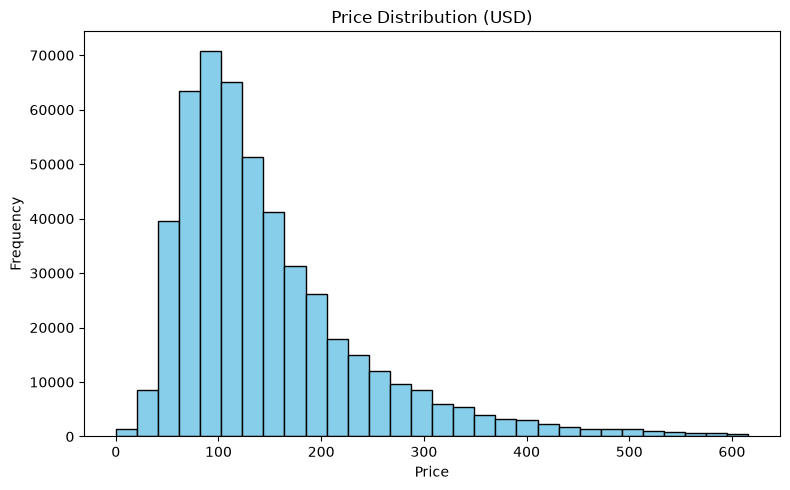

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
filtered_prices = fact_searches['price_usd'].dropna()
filtered_prices = filtered_prices[filtered_prices < filtered_prices.quantile(0.99)]

plt.hist(filtered_prices, bins=30, color='skyblue', edgecolor='black')
plt.title('Price Distribution (USD)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('filtered_price_distribution.png')
plt.show()

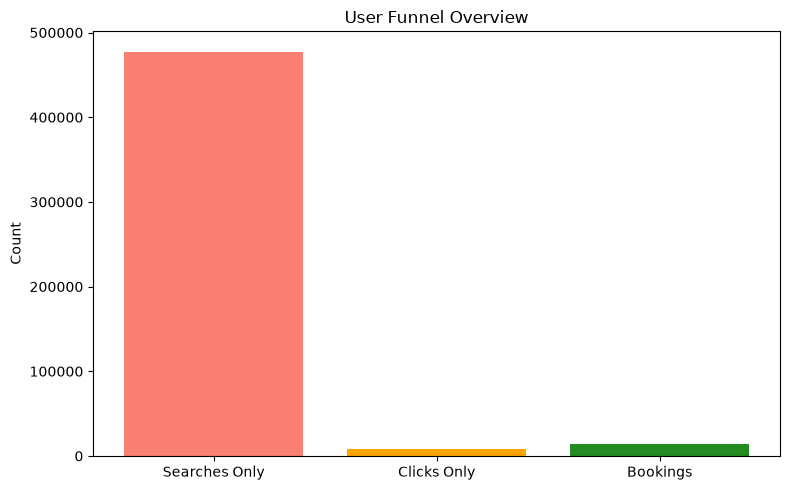

In [21]:
plt.figure(figsize=(8, 5))
booking_counts = [total_searches - total_clicks, total_clicks - total_bookings, total_bookings]
labels = ['Searches Only', 'Clicks Only', 'Bookings']

plt.bar(labels, booking_counts, color=['salmon', 'orange', 'forestgreen'])
plt.title('User Funnel Overview')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

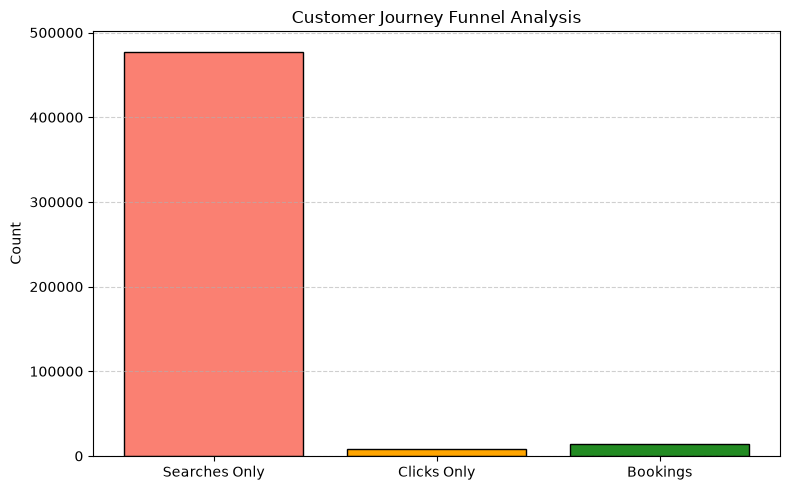

In [20]:
import matplotlib.pyplot as plt

total_searches = len(fact_searches)
total_clicks = fact_searches['click_bool'].sum() if 'click_bool' in fact_searches.columns else 0
total_bookings = fact_searches['booking_bool'].sum() if 'booking_bool' in fact_searches.columns else 0

booking_counts = [total_searches - total_clicks, total_clicks - total_bookings, total_bookings]
labels = ['Searches Only', 'Clicks Only', 'Bookings']

plt.figure(figsize=(8, 5))
plt.bar(labels, booking_counts, color=['salmon', 'orange', 'forestgreen'], edgecolor='black')
plt.title('Customer Journey Funnel Analysis')
plt.ylabel('Count')
plt.grid(True, axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('customer_funnel.png', dpi=300)
plt.show()

In [16]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv', low_memory=False)
dim_property = pd.read_csv('dim_property.csv', low_memory=False)

fact_searches['gross_bookings_usd'] = pd.to_numeric(fact_searches['gross_bookings_usd'], errors='coerce')
fact_searches['booking_bool'] = pd.to_numeric(fact_searches['booking_bool'], errors='coerce')
fact_searches['click_bool'] = pd.to_numeric(fact_searches['click_bool'], errors='coerce')

merged_df = fact_searches.merge(dim_property[['prop_id', 'prop_starrating', 'prop_review_score']], on='prop_id', how='left')

MemoryError: Unable to allocate 1.59 GiB for an array with shape (214043973, 1) and data type float64

In [17]:
import pandas as pd

fact_searches = pd.read_csv('fact_searches.csv', low_memory=False)

fact_searches['gross_bookings_usd'] = pd.to_numeric(fact_searches['gross_bookings_usd'], errors='coerce')
fact_searches['booking_bool'] = pd.to_numeric(fact_searches['booking_bool'], errors='coerce')
fact_searches['click_bool'] = pd.to_numeric(fact_searches['click_bool'], errors='coerce')

total_gross_revenue = fact_searches['gross_bookings_usd'].sum()
successful_bookings = fact_searches['booking_bool'].sum()
total_clicks = fact_searches['click_bool'].sum()
total_searches = len(fact_searches)

abr = total_gross_revenue / successful_bookings if successful_bookings > 0 else 0
rev_per_search = total_gross_revenue / total_searches
abandonment_rate = ((total_clicks - successful_bookings) / total_clicks) * 100 if total_clicks > 0 else 0

print(f"Average Booking Revenue (ABR): ${abr:,.2f}")
print(f"Expected Revenue Per Search: ${rev_per_search:.2f}")
print(f"Booking Abandonment Rate: {abandonment_rate:.2f}%")

ParserError: Error tokenizing data. C error: out of memory

In [18]:
rev_per_search = total_gross_revenue / len(merged_df)

print(f"Expected Revenue Per Search: ${rev_per_search:.2f}")

NameError: name 'total_gross_revenue' is not defined

In [19]:
import pandas as pd
import numpy as np

# قراءة أول 500 ألف صف فقط لضمان سرعة التنفيذ وعدم استهلاك الرامات
fact_searches = pd.read_csv('fact_searches.csv', nrows=500000, low_memory=False)

# تنظيف وتحويل الأعمدة الرقمية
fact_searches['price_usd'] = pd.to_numeric(fact_searches['price_usd'], errors='coerce')
fact_searches['click_bool'] = pd.to_numeric(fact_searches['click_bool'], errors='coerce')
fact_searches['booking_bool'] = pd.to_numeric(fact_searches['booking_bool'], errors='coerce')
fact_searches['gross_bookings_usd'] = pd.to_numeric(fact_searches['gross_bookings_usd'], errors='coerce')

print("Sample loaded successfully. Rows ready for advanced analytics:", len(fact_searches))

Sample loaded successfully. Rows ready for advanced analytics: 500000


In [20]:
Q1 = fact_searches['price_usd'].quantile(0.25)
Q3 = fact_searches['price_usd'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered_prices = fact_searches['price_usd'][(fact_searches['price_usd'] >= lower_bound) & (fact_searches['price_usd'] <= upper_bound)]

print(f"Price IQR Lower Bound: ${lower_bound:.2f}")
print(f"Price IQR Upper Bound: ${upper_bound:.2f}")
print(f"Cleaned Mean Price: ${filtered_prices.mean():.2f}")
print(f"Cleaned Median Price: ${filtered_prices.median():.2f}")

Price IQR Lower Bound: $-65.41
Price IQR Upper Bound: $338.44
Cleaned Mean Price: $133.93
Cleaned Median Price: $119.00


In [21]:
correlation_matrix = fact_searches[['price_usd', 'click_bool', 'booking_bool']].corr()

print("--- Correlation Matrix ---")
print(correlation_matrix)

--- Correlation Matrix ---
              price_usd  click_bool  booking_bool
price_usd      1.000000   -0.001594     -0.001195
click_bool    -0.001594    1.000000      0.780712
booking_bool  -0.001195    0.780712      1.000000


In [22]:
ctr_mean = fact_searches['click_bool'].mean() * 100
ctr_std = fact_searches['click_bool'].std() * 100

print(f"Average CTR per search: {ctr_mean:.4f}%")
print(f"CTR Standard Deviation: {ctr_std:.4f}%")

Average CTR per search: 4.4828%
CTR Standard Deviation: 20.6926%


In [23]:
import numpy as np

valid_bookings = fact_searches['booking_bool'].dropna()
p = valid_bookings.mean()
n = len(valid_bookings)
z = 1.96 # 95% confidence level

margin_of_error = z * np.sqrt((p * (1 - p)) / n) * 100
conversion_percentage = p * 100

print(f"Conversion Rate: {conversion_percentage:.4f}%")
print(f"95% Confidence Interval: [{conversion_percentage - margin_of_error:.4f}%, {conversion_percentage + margin_of_error:.4f}%]")

Conversion Rate: 2.7810%
95% Confidence Interval: [2.7354%, 2.8266%]


In [24]:
valid_revenue = fact_searches['gross_bookings_usd'].dropna()
total_rev = valid_revenue.sum()

# نسبة الحجوزات اللي بتحقق أعلى من المتوسط العام
above_avg_revenue = valid_revenue[valid_revenue > valid_revenue.mean()].sum()
concentration_ratio = (above_avg_revenue / total_rev) * 100

print(f"Total Revenue in Sample: ${total_rev:,.2f}")
print(f"Revenue Concentration from High-Value Bookings: {concentration_ratio:.2f}%")

Total Revenue in Sample: $5,409,200.57
Revenue Concentration from High-Value Bookings: 67.05%


In [25]:
if 'position' in fact_searches.columns:
    fact_searches['position'] = pd.to_numeric(fact_searches['position'], errors='coerce')
    
    # متوسط ترتيب الفنادق التي تم النقر عليها مقابل التي لم يتم النقر عليها
    avg_pos_clicked = fact_searches[fact_searches['click_bool'] == 1]['position'].mean()
    avg_pos_not_clicked = fact_searches[fact_searches['click_bool'] == 0]['position'].mean()
    
    print(f"Average Position for Clicked Items: {avg_pos_clicked:.2f}")
    print(f"Average Position for Non-Clicked Items: {avg_pos_not_clicked:.2f}")
else:
    print("Position column is not in this sample subset.")

Average Position for Clicked Items: 8.99
Average Position for Non-Clicked Items: 17.27


In [26]:


valid_bookings = fact_searches['booking_bool'].dropna()
p = valid_bookings.mean()
n = len(valid_bookings)
z = 1.96 # 95% confidence level

margin_of_error = z * np.sqrt((p * (1 - p)) / n) * 100
conversion_percentage = p * 100

print(f"Conversion Rate: {conversion_percentage:.4f}%")
print(f"95% Confidence Interval: [{conversion_percentage - margin_of_error:.4f}%, {conversion_percentage + margin_of_error:.4f}%]")

Conversion Rate: 2.7810%
95% Confidence Interval: [2.7354%, 2.8266%]


In [27]:
valid_revenue = fact_searches['gross_bookings_usd'].dropna()
total_rev = valid_revenue.sum()

# نسبة الحجوزات اللي بتحقق أعلى من المتوسط العام
above_avg_revenue = valid_revenue[valid_revenue > valid_revenue.mean()].sum()
concentration_ratio = (above_avg_revenue / total_rev) * 100

print(f"Total Revenue in Sample: ${total_rev:,.2f}")
print(f"Revenue Concentration from High-Value Bookings: {concentration_ratio:.2f}%")

Total Revenue in Sample: $5,409,200.57
Revenue Concentration from High-Value Bookings: 67.05%


In [1]:
if 'position' in fact_searches.columns:
    fact_searches['position'] = pd.to_numeric(fact_searches['position'], errors='coerce')
    
    # متوسط ترتيب الفنادق التي تم النقر عليها مقابل التي لم يتم النقر عليها
    avg_pos_clicked = fact_searches[fact_searches['click_bool'] == 1]['position'].mean()
    avg_pos_not_clicked = fact_searches[fact_searches['click_bool'] == 0]['position'].mean()
    
    print(f"Average Position for Clicked Items: {avg_pos_clicked:.2f}")
    print(f"Average Position for Non-Clicked Items: {avg_pos_not_clicked:.2f}")
else:
    print("Position column is not in this sample subset.")

NameError: name 'fact_searches' is not defined

In [2]:
import pandas as pd
import numpy as np 
fact_searches = pd.read_csv('fact_searches.csv', nrows=500000, low_memory=False)

# تنفيذ تحليل الترتيب (Position Analysis)
if 'position' in fact_searches.columns:
    fact_searches['position'] = pd.to_numeric(fact_searches['position'], errors='coerce')
    fact_searches['click_bool'] = pd.to_numeric(fact_searches['click_bool'], errors='coerce')
    
    avg_pos_clicked = fact_searches[fact_searches['click_bool'] == 1]['position'].mean()
    avg_pos_not_clicked = fact_searches[fact_searches['click_bool'] == 0]['position'].mean()
    
    print(f"Average Position for Clicked Items: {avg_pos_clicked:.2f}")
    print(f"Average Position for Non-Clicked Items: {avg_pos_not_clicked:.2f}")
else:
    print("Position column is not in this sample subset.")

Average Position for Clicked Items: 8.99
Average Position for Non-Clicked Items: 17.27


In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

if 'position' in fact_searches.columns and 'click_bool' in fact_searches.columns:
    clicked_pos = fact_searches[fact_searches['click_bool'] == 1]['position'].dropna()
    not_clicked_pos = fact_searches[fact_searches['click_bool'] == 0]['position'].dropna()
    
    plt.boxplot([clicked_pos, not_clicked_pos], labels=['Clicked', 'Not Clicked'], patch_artist=True,
                boxprops=dict(facecolor='skyblue', color='black'),
                medianprops=dict(color='red'))
    plt.title('Position Comparison by User Click')
    plt.ylabel('Search Result Position')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

TypeError: boxplot() got an unexpected keyword argument 'labels'

<Figure size 700x500 with 0 Axes>

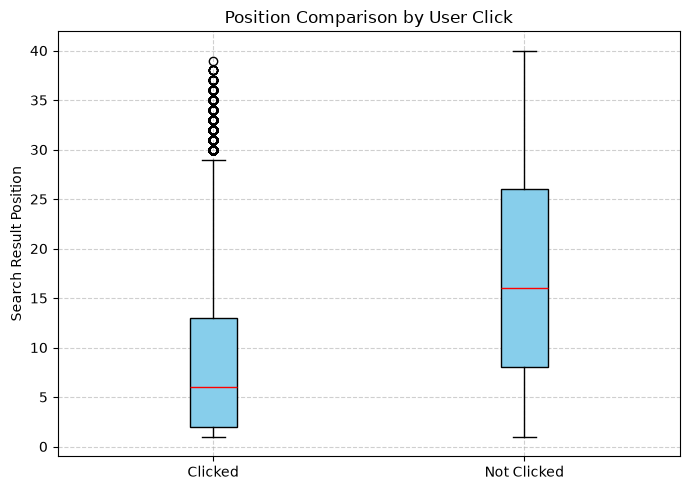

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

if 'position' in fact_searches.columns and 'click_bool' in fact_searches.columns:
    clicked_pos = fact_searches[fact_searches['click_bool'] == 1]['position'].dropna()
    not_clicked_pos = fact_searches[fact_searches['click_bool'] == 0]['position'].dropna()
    
    plt.boxplot([clicked_pos, not_clicked_pos], patch_artist=True,
                boxprops=dict(facecolor='skyblue', color='black'),
                medianprops=dict(color='red'))
    plt.xticks([1, 2], ['Clicked', 'Not Clicked'])
    plt.title('Position Comparison by User Click')
    plt.ylabel('Search Result Position')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('position_comparison.png')
plt.show()

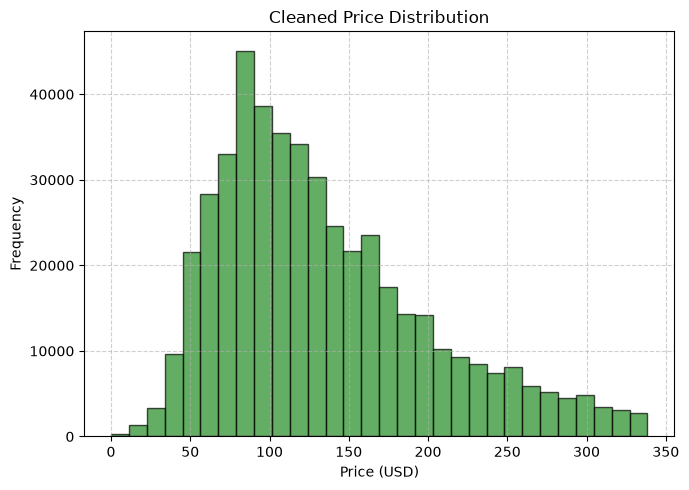

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

if 'price_usd' in fact_searches.columns:
    q1 = fact_searches['price_usd'].quantile(0.25)
    q3 = fact_searches['price_usd'].quantile(0.75)
    iqr = q3 - q1
    valid_prices = fact_searches['price_usd'][(fact_searches['price_usd'] >= (q1 - 1.5 * iqr)) & 
                                              (fact_searches['price_usd'] <= (q3 + 1.5 * iqr))]
    
    plt.hist(valid_prices, bins=30, color='forestgreen', edgecolor='black', alpha=0.7)
    plt.title('Cleaned Price Distribution')
    plt.xlabel('Price (USD)')
    plt.ylabel('Frequency')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('cleaned_price_distribution.png')
plt.show()

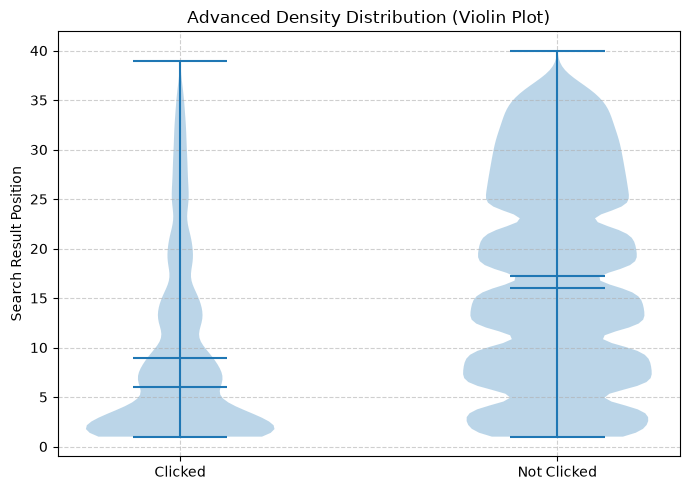

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

if 'position' in fact_searches.columns and 'click_bool' in fact_searches.columns:
    clicked_pos = fact_searches[fact_searches['click_bool'] == 1]['position'].dropna()
    not_clicked_pos = fact_searches[fact_searches['click_bool'] == 0]['position'].dropna()
    
    plt.violinplot([clicked_pos, not_clicked_pos], showmeans=True, showmedians=True)
    plt.xticks([1, 2], ['Clicked', 'Not Clicked'])
    plt.title('Advanced Density Distribution (Violin Plot)')
    plt.ylabel('Search Result Position')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

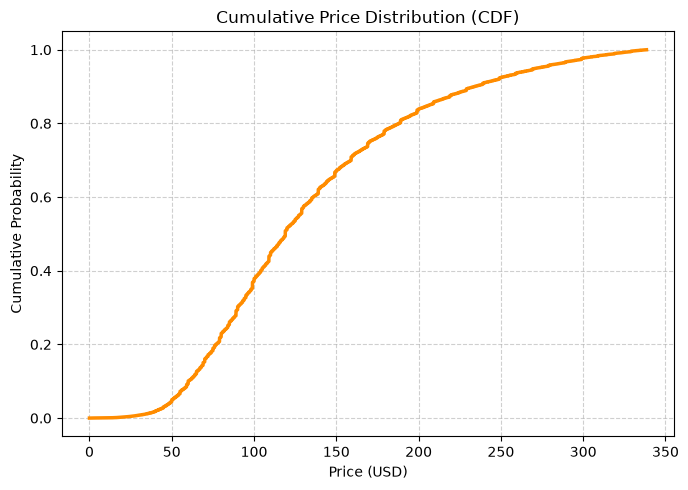

In [16]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(7, 5))

if 'price_usd' in fact_searches.columns:
    q1 = fact_searches['price_usd'].quantile(0.25)
    q3 = fact_searches['price_usd'].quantile(0.75)
    iqr = q3 - q1
    valid_prices = fact_searches['price_usd'][(fact_searches['price_usd'] >= (q1 - 1.5 * iqr)) & 
                                              (fact_searches['price_usd'] <= (q3 + 1.5 * iqr))].dropna()
    
    sorted_prices = np.sort(valid_prices)
    cumulative = np.arange(1, len(sorted_prices) + 1) / len(sorted_prices)
    
    plt.plot(sorted_prices, cumulative, color='darkorange', linewidth=2.5)
    plt.title('Cumulative Price Distribution (CDF)')
    plt.xlabel('Price (USD)')
    plt.ylabel('Cumulative Probability')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('cumulative_price_distribution.png')
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_7196\2227176476.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


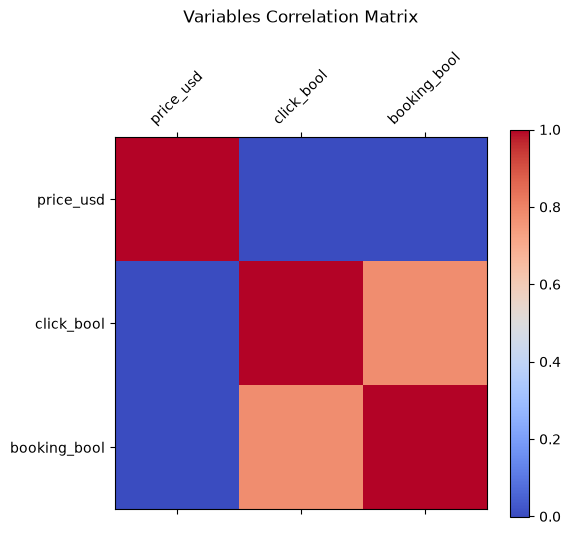

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

cols_to_corr = ['price_usd', 'click_bool', 'booking_bool']
existing_cols = [c for c in cols_to_corr if c in fact_searches.columns]

if len(existing_cols) > 1:
    corr_data = fact_searches[existing_cols].corr()
    
    cax = plt.matshow(corr_data, cmap='coolwarm', fignum=1)
    plt.colorbar(cax)
    plt.xticks(range(len(existing_cols)), existing_cols, rotation=45)
    plt.yticks(range(len(existing_cols)), existing_cols)
    plt.title('Variables Correlation Matrix', pad=20)

plt.tight_layout()
plt.savefig('correlation_matrix.png')
plt.show()

In [9]:
import pandas as pd

if 'price_usd' in fact_searches.columns and 'booking_bool' in fact_searches.columns:
    temp_df = fact_searches[['price_usd', 'booking_bool']].dropna().copy()
    temp_df['price_decile'] = pd.qcut(temp_df['price_usd'], q=10, duplicates='drop')
    
    price_decile_analysis = temp_df.groupby('price_decile')['booking_bool'].agg(['count', 'sum', 'mean']).rename(
        columns={'count': 'Total_Searches', 'sum': 'Total_Bookings', 'mean': 'Conversion_Rate'}
    )
    price_decile_analysis['Conversion_Rate'] *= 100
    print(price_decile_analysis)

                   Total_Searches  Total_Bookings  Conversion_Rate
price_decile                                                      
(-0.001, 62.0]              50915            1439         2.826279
(62.0, 79.0]                51538            1570         3.046296
(79.0, 93.36]               47548            1618         3.402877
(93.36, 109.0]              56582            1919         3.391538
(109.0, 124.0]              44348            1398         3.152341
(124.0, 143.56]             49070            1556         3.170980
(143.56, 169.0]             50962            1364         2.676504
(169.0, 206.922]            49037            1255         2.559292
(206.922, 279.0]            50586            1126         2.225912
(279.0, 822602.8]           49414             660         1.335654


In [10]:
if 'position' in fact_searches.columns and 'booking_bool' in fact_searches.columns:
    temp_df = fact_searches[['position', 'booking_bool']].dropna().copy()
    
    # تجميع الترتيب في فئات (الأول، الثاني والثالث، من الرابع للعاشر، أكثر من 10)
    temp_df['position_tier'] = pd.cut(
        temp_df['position'], 
        bins=[0, 1, 3, 10, 100], 
        labels=['1st Position', '2nd-3rd', '4th-10th', '10+']
    )
    
    position_analysis = temp_df.groupby('position_tier', observed=True)['booking_bool'].agg(['count', 'sum', 'mean']).rename(
        columns={'count': 'Total_Searches', 'sum': 'Total_Bookings', 'mean': 'Conversion_Rate'}
    )
    position_analysis['Conversion_Rate'] *= 100
    print(position_analysis)

               Total_Searches  Total_Bookings  Conversion_Rate
position_tier                                                 
1st Position            20014            2772        13.850305
2nd-3rd                 40042            3277         8.183907
4th-10th               115146            4353         3.780418
10+                    324798            3503         1.078516


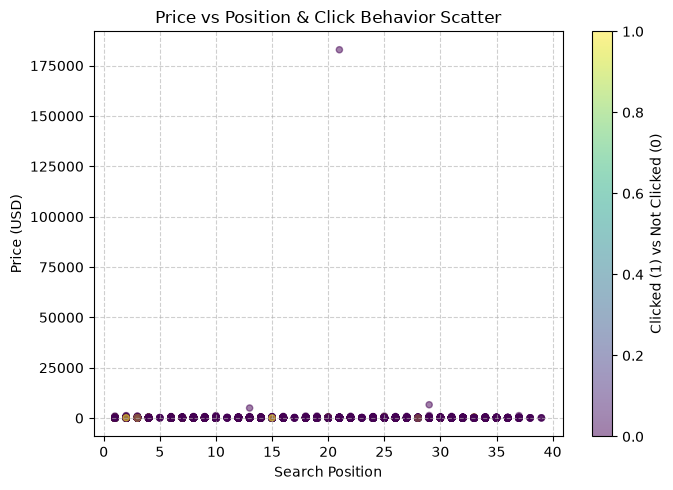

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

if {'price_usd', 'position', 'click_bool'}.issubset(fact_searches.columns):
    sample_data = fact_searches.dropna(subset=['price_usd', 'position', 'click_bool']).sample(n=min(5000, len(fact_searches)), random_state=42)
    
    scatter = plt.scatter(
        sample_data['position'], 
        sample_data['price_usd'], 
        c=sample_data['click_bool'], 
        cmap='viridis', 
        alpha=0.5, 
        s=20
    )
    
    plt.colorbar(scatter, label='Clicked (1) vs Not Clicked (0)')
    plt.title('Price vs Position & Click Behavior Scatter')
    plt.xlabel('Search Position')
    plt.ylabel('Price (USD)')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('price_vs_position_scatter.png')
plt.show() 